# AI-Based Hospital Readmission Prediction System

# 1. Data Understanding

# Introduction

 This notebook focuses on understanding the hospital readmission dataset before
 performing data preprocessing and machine learning.

 The main objectives are:
 - Understand the structure of the dataset
 - Identify numerical and categorical variables
 - Check missing values
 - Identify duplicate records
 - Understand the target variable
 - Examine the distribution of readmission outcomes

 The target variable is `readmitted`, which indicates whether a patient was
 readmitted to the hospital.

# Import the required libraries

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

# Display floating-point values with two decimal places
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


# 2. Load the Dataset

 In this step, we load the original hospital readmission dataset.

 The raw dataset is kept unchanged so that the original data remains available
 for reference and reproducibility.

In [2]:
# Load the original hospital readmission dataset

df = pd.read_csv("diabetic_data.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


# 3. First Look at the Dataset

 We will display the first five records to understand how the data is organized.

In [3]:
# Display the first five rows of the dataset

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


# 4. Dataset Shape

 The shape tells us:
 - Number of rows = number of patient records
 - Number of columns = number of variables/features

In [4]:
# Display the number of rows and columns

rows, columns = df.shape

print(f"Number of rows    : {rows}")
print(f"Number of columns : {columns}")

Number of rows    : 101766
Number of columns : 50


# 5. Column Names

 Let's examine all the columns available in the dataset.

In [5]:
# Display all column names

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. encounter_id
2. patient_nbr
3. race
4. gender
5. age
6. weight
7. admission_type_id
8. discharge_disposition_id
9. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted


# 6. Dataset Information

 This step provides information about:
 - Column names
 - Data types
 - Number of non-null values
 - Memory usage

In [6]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

# 7. Statistical Summary

 The statistical summary helps us understand numerical variables such as:
 - Age-related encoded values
 - Length of hospital stay
 - Number of medications
 - Number of procedures
 - Number of diagnoses
 - Previous hospital visits

In [7]:
# Generate statistical summary for numerical columns

df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00,101766.00
mean,165201645.62,54330400.69,2.02,3.72,5.75,4.40,43.10,1.34,16.02,0.37,0.20,0.64,7.42
std,102640295.98,38696359.35,1.45,5.28,4.06,2.99,19.67,1.71,8.13,1.27,0.93,1.26,1.93
min,12522.00,135.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,84961194.00,23413221.00,1.00,1.00,1.00,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,152388987.00,45505143.00,1.00,1.00,7.00,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,230270887.50,87545949.75,3.00,4.00,7.00,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,443867222.00,189502619.00,8.00,28.00,25.00,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


# 8. Initial Missing-Value Check

 First, we check for standard missing values represented as NaN.

In [8]:
# Count missing values in each column

missing_values = df.isnull().sum()

# Display columns containing missing values
missing_values[missing_values > 0].sort_values(ascending=False)

max_glu_serum    96420
A1Cresult        84748
dtype: int64

# 9. Identify Unknown Values

 The dataset also contains missing/unknown values represented by `?`.

 These values need to be identified because machine learning algorithms cannot
 properly interpret `?` as a meaningful category in many preprocessing steps.

In [9]:
# Count '?' values in every column

question_mark_counts = (df == "?").sum()

# Display columns containing '?'
question_mark_counts[question_mark_counts > 0].sort_values(ascending=False)

weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

# 10. Convert Unknown Values to NaN

 We convert `?` into `NaN` so that all missing values can be handled consistently
 during the preprocessing stage.

In [10]:
# Replace '?' with NaN

df = df.replace("?", np.nan)

print("Unknown '?' values have been converted to NaN.")

Unknown '?' values have been converted to NaN.


In [11]:
# Check missing values again after conversion

missing_after_conversion = df.isnull().sum()

missing_after_conversion[missing_after_conversion > 0].sort_values(
    ascending=False
)

weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

# 11. Missing-Value Percentage

 Instead of looking only at the number of missing values, we calculate the
 percentage of missing values in each column.

 This helps identify columns with a very large amount of missing information.

In [12]:
# Calculate missing-value percentage for every column

missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

# Display only columns containing missing values
missing_percentage[missing_percentage > 0].to_frame(
    name="Missing_Percentage"
)

,Missing_Percentage
weight,96.86
max_glu_serum,94.75
A1Cresult,83.28
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


# 12. Duplicate Records

 We check whether the dataset contains duplicate patient records.

In [13]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate records: {duplicate_count}")

Number of duplicate records: 0


# 13. Target Variable

 The target variable is `readmitted`.

 It contains three outcomes:

 - `<30`  : patient was readmitted within 30 days
 - `>30`  : patient was readmitted after 30 days
  - `NO`   : patient was not readmitted

 For the machine learning classification task, the `<30` category will later
 be treated as the positive class.

In [14]:
# Display the unique target classes

print("Target classes:")
print(df["readmitted"].unique())

Target classes:
['NO' '>30' '<30']


In [15]:
# Count records in each target class

target_counts = df["readmitted"].value_counts()

print(target_counts)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [16]:
# Calculate target-class percentages

target_percentage = (
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_percentage)

readmitted
NO    53.91
>30   34.93
<30   11.16
Name: proportion, dtype: float64


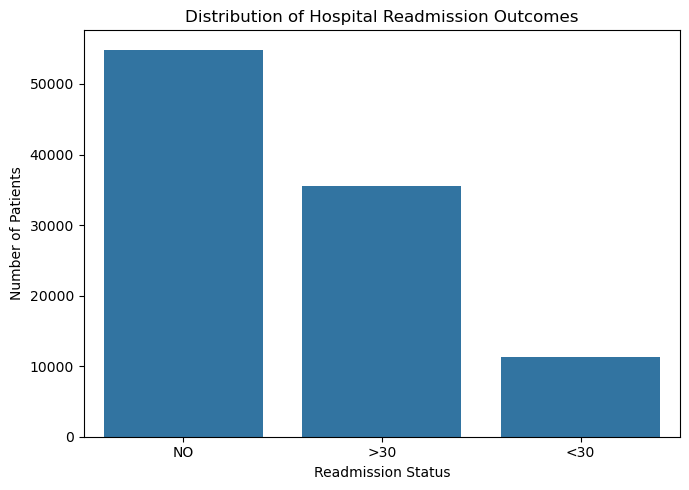

In [17]:
# Visualize target distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=df["readmitted"].value_counts().index
)

plt.title("Distribution of Hospital Readmission Outcomes")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

# 14. Data Types

 We separate the variables into numerical and categorical groups.

 This distinction will be important during data preprocessing because numerical
 and categorical variables require different preprocessing techniques.

In [18]:
# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [19]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


# 15. Unique Values in Categorical Variables

 We examine the number of unique values in categorical variables to understand
 their structure and identify variables with many categories.

In [20]:
# Display the number of unique values for categorical columns

categorical_unique_values = (
    df[categorical_columns]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

categorical_unique_values.to_frame(name="Number_of_Unique_Values")

,Number_of_Unique_Values
diag_3,790
diag_2,749
diag_1,717
medical_specialty,73
payer_code,18
age,10
weight,10
race,6
glipizide,4
glyburide-metformin,4


# 16. Important Categorical Variables

 Let's inspect some important categorical variables related to patient
 demographics and diabetes treatment.

In [21]:
# Display value counts for selected categorical variables

important_columns = [
    "gender",
    "race",
    "age",
    "diabetesMed",
    "insulin",
    "change"
]

for column in important_columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {column}")
    print(f"{'=' * 50}")
    print(df[column].value_counts(dropna=False).head(15))


Column: gender
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Column: race
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Column: age
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

Column: diabetesMed
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64

Column: insulin
insulin
No        47383
Steady    30849
Down      12218
Up        11316
Name: count, dtype: int64

Column: change
change
No    54755
Ch    47011
Name: count, dtype: int64


# 17. Final Data Understanding Summary

 At this stage, we have:
 - Loaded the original dataset
 - Examined its structure and dimensions
 - Identified numerical and categorical variables
 - Identified unknown values represented by `?`
 - Converted `?` into `NaN`
 - Examined missing values
 - Checked duplicate records
 - Studied the target variable
 - Examined the distribution of readmission outcomes

 The dataset is now ready for the preprocessing stage.

 The original raw CSV file remains unchanged; the missing-value conversion is
 performed only inside the working DataFrame.

In [22]:
# Display a concise final summary

print("FINAL DATA UNDERSTANDING SUMMARY")
print("-" * 50)
print(f"Rows                 : {df.shape[0]}")
print(f"Columns              : {df.shape[1]}")
print(f"Numerical columns    : {len(numerical_columns)}")
print(f"Categorical columns  : {len(categorical_columns)}")
print(f"Duplicate records    : {duplicate_count}")
print(f"Target column        : readmitted")

print("\nTarget distribution:")
print(df["readmitted"].value_counts(dropna=False))

print("\nData understanding completed successfully.")

FINAL DATA UNDERSTANDING SUMMARY
--------------------------------------------------
Rows                 : 101766
Columns              : 50
Numerical columns    : 13
Categorical columns  : 37
Duplicate records    : 0
Target column        : readmitted

Target distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Data understanding completed successfully.
